In [1]:
import re, random, warnings
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, confusion_matrix

warnings.filterwarnings("ignore")
SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
plt.rcParams["figure.figsize"] = (10, 4); plt.rcParams["axes.grid"] = True
print("PyTorch version:", torch.__version__)
print("Device:", device)

PyTorch version: 2.11.0+cu130
Device: cuda


In [4]:
import io
df = None
try:
    from google.colab import files            # only exists in Google Colab
    print("Upload spam.csv (or press Cancel to download it automatically)...")
    up = files.upload()
    if up:
        name = list(up.keys())[0]
        df = pd.read_csv(io.BytesIO(up[name]), encoding="latin-1")
except Exception as e:
    print("Upload skipped:", type(e).__name__)

if df is None:
    url = "https://raw.githubusercontent.com/mohitgupta-omg/Kaggle-SMS-Spam-Collection-Dataset-/master/spam.csv"
    df = pd.read_csv(url, encoding="latin-1")
    print("Loaded dataset from public URL.")

df = df[["v1", "v2"]].rename(columns={"v1": "label", "v2": "text"}).dropna().reset_index(drop=True)
print("Shape:", df.shape)
df.head()

Upload spam.csv (or press Cancel to download it automatically)...


Saving spam.csv to spam (1).csv
Shape: (5572, 2)


,label,text
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


In [5]:
counts = df["label"].value_counts()
print("Class counts:\n", counts.to_string())
print("\nClass share (%):\n", (counts / len(df) * 100).round(2).to_string())
df["n_words"] = df["text"].str.split().str.len()
print("\nWords per message:")
print(df.groupby("label")["n_words"].describe().round(1).to_string())
print("\nDuplicate messages:", int(df["text"].duplicated().sum()))
print("\nExample messages:")
for lab in ["ham", "spam"]:
    for t in df[df.label == lab]["text"].head(2):
        print(f"[{lab}] {t[:110]}")

Class counts:
 label
ham     4825
spam     747

Class share (%):
 label
ham     86.59
spam    13.41

Words per message:
        count  mean   std  min   25%   50%   75%    max
label                                                  
ham    4825.0  14.2  11.4  1.0   7.0  11.0  19.0  171.0
spam    747.0  23.9   5.8  2.0  22.0  25.0  28.0   35.0

Duplicate messages: 403

Example messages:
[ham] Go until jurong point, crazy.. Available only in bugis n great world la e buffet... Cine there got amore wat..
[ham] Ok lar... Joking wif u oni...
[spam] Free entry in 2 a wkly comp to win FA Cup final tkts 21st May 2005. Text FA to 87121 to receive entry question
[spam] FreeMsg Hey there darling it's been 3 week's now and no word back! I'd like some fun you up for it still? Tb o


In [4]:
df.describe()

,Temp
count,3650.000000
mean,11.177753
std,4.071837
min,0.000000
25%,8.300000
50%,11.000000
75%,14.000000
max,26.300000


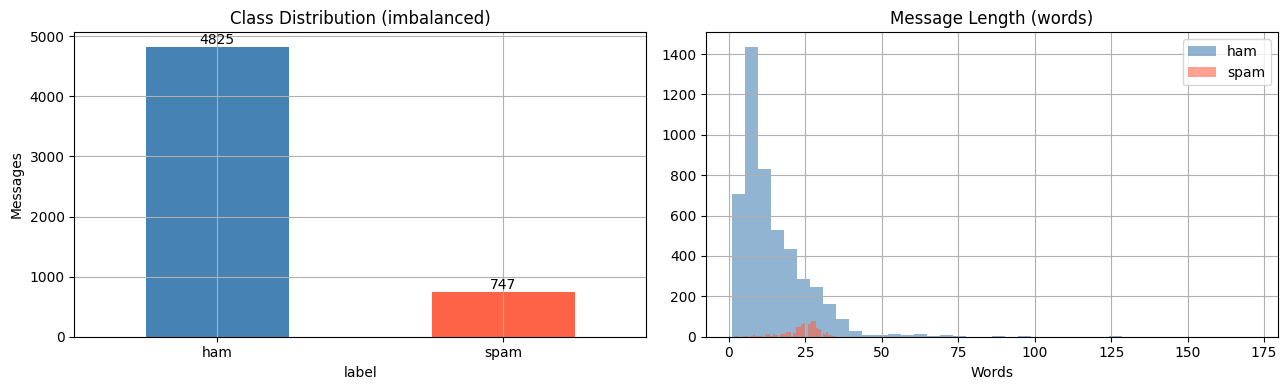

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
counts.plot(kind="bar", ax=ax[0], color=["steelblue", "tomato"], rot=0)
ax[0].set_title("Class Distribution (imbalanced)"); ax[0].set_ylabel("Messages")
for i, v in enumerate(counts): ax[0].text(i, v, str(v), ha="center", va="bottom")
for lab, c in [("ham", "steelblue"), ("spam", "tomato")]:
    ax[1].hist(df[df.label == lab]["n_words"], bins=40, alpha=0.6, color=c, label=lab)
ax[1].set_title("Message Length (words)"); ax[1].set_xlabel("Words"); ax[1].legend()
plt.tight_layout(); plt.show()

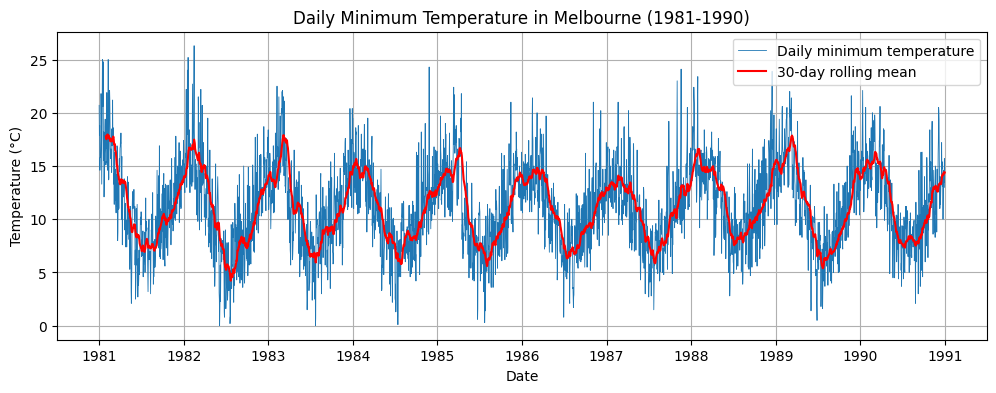

In [6]:
# Visualisation 1: full series with 30-day rolling mean
plt.figure()
plt.plot(df.index, df["Temp"], lw=0.6, label="Daily minimum temperature")
plt.plot(df.index, df["Temp"].rolling(30).mean(), color="red", lw=1.5, label="30-day rolling mean")
plt.title("Daily Minimum Temperature in Melbourne (1981-1990)")
plt.xlabel("Date"); plt.ylabel("Temperature (°C)"); plt.legend()
plt.show()

In [7]:
label2id = {"ham": 0, "spam": 1}
y_all = df["label"].map(label2id).values
texts = df["text"].tolist()
idx = np.arange(len(df))

train_idx, test_idx = train_test_split(idx, test_size=0.20, random_state=SEED, stratify=y_all)      # fixed 80/20
tr_idx, val_idx = train_test_split(train_idx, test_size=0.10, random_state=SEED, stratify=y_all[train_idx])

def tokenize(t):
    return re.findall(r"[a-z]+|\d+|[^\w\s]", t.lower())

MAX_VOCAB, MIN_FREQ, MAXLEN = 8000, 2, 60
counter = Counter(tok for i in tr_idx for tok in tokenize(texts[i]))          # TRAIN split only
itos = ["<pad>", "<unk>"] + [w for w, c in counter.most_common(MAX_VOCAB - 2) if c >= MIN_FREQ]
stoi = {w: i for i, w in enumerate(itos)}

def encode_split(indices):
    seqs = [[stoi.get(tok, 1) for tok in tokenize(texts[i])][:MAXLEN] for i in indices]
    lengths = torch.tensor([max(len(s), 1) for s in seqs])
    X = torch.zeros(len(seqs), MAXLEN, dtype=torch.long)
    for k, s in enumerate(seqs):
        if s: X[k, :len(s)] = torch.tensor(s)
    return X, lengths, torch.tensor(y_all[indices])

X_tr, L_tr, y_tr = encode_split(tr_idx)
X_va, L_va, y_va = encode_split(val_idx)
X_te, L_te, y_te = encode_split(test_idx)

print(f"Messages: {len(df)} -> train {len(tr_idx)} | validation {len(val_idx)} | test {len(test_idx)}  (80/20 split of the whole set)")
print("Vocabulary size:", len(itos))
print("X_train:", tuple(X_tr.shape), "| lengths:", tuple(L_tr.shape), "| y_train:", tuple(y_tr.shape))
print("X_val:  ", tuple(X_va.shape), "| X_test:", tuple(X_te.shape))
print("Spam share  train %.1f%% | val %.1f%% | test %.1f%%" % (100*y_tr.float().mean(), 100*y_va.float().mean(), 100*y_te.float().mean()))
print("\nExample message:", texts[tr_idx[0]][:80])
print("Tokens:         ", tokenize(texts[tr_idx[0]])[:12])
print("Encoded (ids):  ", X_tr[0, :12].tolist(), "... length", int(L_tr[0]))

Messages: 5572 -> train 4011 | validation 446 | test 1115  (80/20 split of the whole set)
Vocabulary size: 3464
X_train: (4011, 60) | lengths: (4011,) | y_train: (4011,)
X_val:   (446, 60) | X_test: (1115, 60)
Spam share  train 13.4% | val 13.5% | test 13.4%

Example message: FRAN I DECIDED 2 GO N E WAY IM COMPLETELY BROKE AN KNACKERED I GOT UP BOUT 3 C U
Tokens:          ['fran', 'i', 'decided', '2', 'go', 'n', 'e', 'way', 'im', 'completely', 'broke', 'an']
Encoded (ids):   [1847, 3, 768, 21, 69, 102, 171, 156, 192, 1197, 1353, 153] ... length 36


In [8]:
majority = int(torch.bincount(y_tr).argmax())
baseline_acc = float((y_te == majority).float().mean())
TARGET = 0.96
print(f"Majority class: {'ham' if majority == 0 else 'spam'}")
print(f"Baseline test accuracy: {baseline_acc*100:.2f}%")
print(f"Target test accuracy:   {TARGET*100:.0f}%")

Majority class: ham
Baseline test accuracy: 86.64%
Target test accuracy:   96%


In [9]:
class SeqClassifier(nn.Module):
    def __init__(self, cell="LSTM", vocab_size=len(itos), emb_dim=64, hidden=128, n_classes=2, dropout=0.3):
        super().__init__()
        self.cell = cell
        self.emb = nn.Embedding(vocab_size, emb_dim, padding_idx=0)
        self.rnn = {"RNN": nn.RNN, "LSTM": nn.LSTM}[cell](emb_dim, hidden, batch_first=True)
        self.drop = nn.Dropout(dropout)
        self.fc = nn.Linear(hidden, n_classes)

    def forward(self, x, lengths):
        e = self.drop(self.emb(x))
        packed = nn.utils.rnn.pack_padded_sequence(e, lengths.cpu(), batch_first=True, enforce_sorted=False)
        _, h = self.rnn(packed)
        h_last = h[0][-1] if self.cell == "LSTM" else h[-1]      # LSTM returns (h_n, c_n)
        return self.fc(self.drop(h_last))

for cell in ["RNN", "LSTM"]:
    m = SeqClassifier(cell)
    n_params = sum(p.numel() for p in m.parameters())
    print(f"{cell}: {n_params:,} trainable parameters")
print()
print(SeqClassifier("LSTM"))

RNN: 246,786 trainable parameters
LSTM: 321,282 trainable parameters

SeqClassifier(
  (emb): Embedding(3464, 64, padding_idx=0)
  (rnn): LSTM(64, 128, batch_first=True)
  (drop): Dropout(p=0.3, inplace=False)
  (fc): Linear(in_features=128, out_features=2, bias=True)
)


In [10]:
BATCH, EPOCHS, LR = 64, 15, 1e-3
train_loader = DataLoader(TensorDataset(X_tr, L_tr, y_tr), batch_size=BATCH, shuffle=True)
val_loader   = DataLoader(TensorDataset(X_va, L_va, y_va), batch_size=256)
test_loader  = DataLoader(TensorDataset(X_te, L_te, y_te), batch_size=256)
criterion = nn.CrossEntropyLoss()

def run_epoch(model, loader, optimizer=None):
    train = optimizer is not None
    model.train(train)
    tot_loss, correct, n = 0.0, 0, 0
    with torch.set_grad_enabled(train):
        for xb, lb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            out = model(xb, lb)
            loss = criterion(out, yb)
            if train:
                optimizer.zero_grad(); loss.backward()
                nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                optimizer.step()
            tot_loss += loss.item() * len(yb); correct += (out.argmax(1) == yb).sum().item(); n += len(yb)
    return tot_loss / n, correct / n

def train_model(cell):
    torch.manual_seed(SEED)
    model = SeqClassifier(cell).to(device)
    opt = torch.optim.Adam(model.parameters(), lr=LR)
    hist = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
    best_loss, best_state, best_ep = float("inf"), None, 0
    for ep in range(1, EPOCHS + 1):
        tl, ta = run_epoch(model, train_loader, opt)
        vl, va = run_epoch(model, val_loader)
        for k, v in zip(hist, [tl, vl, ta, va]): hist[k].append(v)
        if vl < best_loss:
            best_loss, best_ep = vl, ep
            best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
        print(f"Epoch {ep:2d}/{EPOCHS} | train loss {tl:.4f} acc {ta:.4f} | val loss {vl:.4f} acc {va:.4f}")
    model.load_state_dict(best_state)
    hist["best_epoch"] = best_ep
    print(f"\nBest epoch (lowest validation loss): {best_ep}")
    return model, hist

In [11]:
rnn_model, rnn_hist = train_model("RNN")

Epoch  1/15 | train loss 0.3518 acc 0.8544 | val loss 0.2083 acc 0.9260
Epoch  2/15 | train loss 0.2055 acc 0.9262 | val loss 0.1343 acc 0.9619
Epoch  3/15 | train loss 0.1458 acc 0.9469 | val loss 0.1432 acc 0.9641
Epoch  4/15 | train loss 0.1187 acc 0.9634 | val loss 0.1006 acc 0.9753
Epoch  5/15 | train loss 0.1271 acc 0.9579 | val loss 0.1172 acc 0.9686
Epoch  6/15 | train loss 0.0930 acc 0.9681 | val loss 0.1156 acc 0.9664
Epoch  7/15 | train loss 0.0731 acc 0.9786 | val loss 0.1072 acc 0.9686
Epoch  8/15 | train loss 0.0646 acc 0.9808 | val loss 0.1255 acc 0.9641
Epoch  9/15 | train loss 0.0671 acc 0.9788 | val loss 0.1426 acc 0.9686
Epoch 10/15 | train loss 0.0588 acc 0.9828 | val loss 0.0745 acc 0.9776
Epoch 11/15 | train loss 0.0404 acc 0.9878 | val loss 0.0846 acc 0.9798
Epoch 12/15 | train loss 0.0498 acc 0.9865 | val loss 0.0854 acc 0.9776
Epoch 13/15 | train loss 0.0621 acc 0.9811 | val loss 0.1167 acc 0.9686
Epoch 14/15 | train loss 0.0469 acc 0.9888 | val loss 0.1016 acc

In [12]:
lstm_model, lstm_hist = train_model("LSTM")

Epoch  1/15 | train loss 0.3578 acc 0.8671 | val loss 0.2329 acc 0.9238
Epoch  2/15 | train loss 0.1682 acc 0.9417 | val loss 0.1007 acc 0.9753
Epoch  3/15 | train loss 0.0980 acc 0.9696 | val loss 0.0855 acc 0.9776
Epoch  4/15 | train loss 0.0717 acc 0.9783 | val loss 0.1023 acc 0.9731
Epoch  5/15 | train loss 0.0537 acc 0.9838 | val loss 0.0627 acc 0.9821
Epoch  6/15 | train loss 0.0417 acc 0.9858 | val loss 0.0831 acc 0.9753
Epoch  7/15 | train loss 0.0386 acc 0.9900 | val loss 0.0650 acc 0.9798
Epoch  8/15 | train loss 0.0291 acc 0.9905 | val loss 0.0827 acc 0.9798
Epoch  9/15 | train loss 0.0229 acc 0.9935 | val loss 0.0577 acc 0.9821
Epoch 10/15 | train loss 0.0190 acc 0.9938 | val loss 0.1121 acc 0.9776
Epoch 11/15 | train loss 0.0185 acc 0.9943 | val loss 0.0850 acc 0.9821
Epoch 12/15 | train loss 0.0160 acc 0.9950 | val loss 0.0664 acc 0.9865
Epoch 13/15 | train loss 0.0150 acc 0.9960 | val loss 0.0572 acc 0.9910
Epoch 14/15 | train loss 0.0119 acc 0.9965 | val loss 0.0656 acc

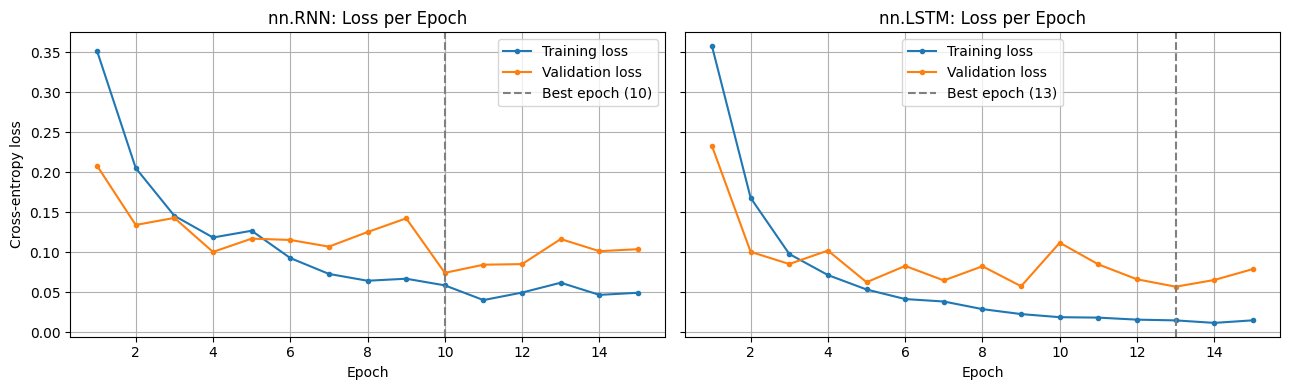

In [13]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
for a, name, h in [(ax[0], "nn.RNN", rnn_hist), (ax[1], "nn.LSTM", lstm_hist)]:
    ep = range(1, EPOCHS + 1)
    a.plot(ep, h["train_loss"], marker="o", ms=3, label="Training loss")
    a.plot(ep, h["val_loss"], marker="o", ms=3, label="Validation loss")
    a.axvline(h["best_epoch"], color="gray", ls="--", label=f"Best epoch ({h['best_epoch']})")
    a.set_title(f"{name}: Loss per Epoch"); a.set_xlabel("Epoch"); a.legend()
ax[0].set_ylabel("Cross-entropy loss")
plt.tight_layout(); plt.show()

In [14]:
@torch.no_grad()
def predict(model, loader):
    model.eval(); preds = []
    for xb, lb, yb in loader:
        preds.append(model(xb.to(device), lb).argmax(1).cpu())
    return torch.cat(preds).numpy()

y_true = y_te.numpy()
results, preds = {}, {}
for name, model, hist in [("nn.RNN", rnn_model, rnn_hist), ("nn.LSTM", lstm_model, lstm_hist)]:
    p = predict(model, test_loader); preds[name] = p
    pr, rc, f1, _ = precision_recall_fscore_support(y_true, p, pos_label=1, average="binary")
    results[name] = {"test_acc": accuracy_score(y_true, p), "spam_precision": pr, "spam_recall": rc, "spam_f1": f1,
                     "best_val_acc": hist["val_acc"][hist["best_epoch"] - 1]}

final_name = max(results, key=lambda k: results[k]["best_val_acc"])     # chosen on VALIDATION accuracy only
table = pd.DataFrame(results).T
table.loc["Majority baseline"] = [baseline_acc, np.nan, np.nan, np.nan, np.nan]
table["Target"] = TARGET
print((table[["test_acc", "spam_precision", "spam_recall", "spam_f1", "best_val_acc", "Target"]] * 1).round(4).to_string())
print(f"\nFinal model (best validation accuracy): {final_name}")
print(f"Test accuracy: {results[final_name]['test_acc']*100:.2f}%  |  baseline {baseline_acc*100:.2f}%  |  target {TARGET*100:.0f}%")
print("Target reached:", results[final_name]["test_acc"] >= TARGET)

                   test_acc  spam_precision  spam_recall  spam_f1  best_val_acc  Target
nn.RNN               0.9794          0.9257       0.9195   0.9226        0.9776    0.96
nn.LSTM              0.9839          0.9456       0.9329   0.9392        0.9910    0.96
Majority baseline    0.8664             NaN          NaN      NaN           NaN    0.96

Final model (best validation accuracy): nn.LSTM
Test accuracy: 98.39%  |  baseline 86.64%  |  target 96%
Target reached: True


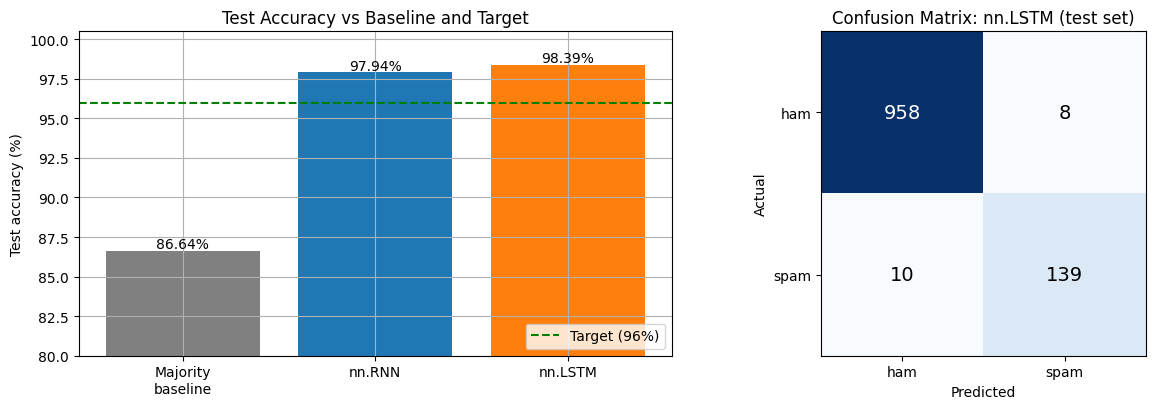

Confusion matrix [rows = actual ham/spam, columns = predicted ham/spam]:
 [[958   8]
 [ 10 139]]


In [15]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
names = ["Majority\nbaseline", "nn.RNN", "nn.LSTM"]
accs = [baseline_acc * 100, results["nn.RNN"]["test_acc"] * 100, results["nn.LSTM"]["test_acc"] * 100]
bars = ax[0].bar(names, accs, color=["gray", "tab:blue", "tab:orange"])
ax[0].axhline(TARGET * 100, color="green", ls="--", label=f"Target ({TARGET*100:.0f}%)")
ax[0].set_ylim(80, 100.5); ax[0].set_ylabel("Test accuracy (%)"); ax[0].set_title("Test Accuracy vs Baseline and Target"); ax[0].legend(loc="lower right")
for b, v in zip(bars, accs): ax[0].text(b.get_x() + b.get_width() / 2, v + 0.15, f"{v:.2f}%", ha="center")

cm = confusion_matrix(y_true, preds[final_name])
im = ax[1].imshow(cm, cmap="Blues"); ax[1].grid(False)
ax[1].set_xticks([0, 1]); ax[1].set_xticklabels(["ham", "spam"]); ax[1].set_yticks([0, 1]); ax[1].set_yticklabels(["ham", "spam"])
ax[1].set_xlabel("Predicted"); ax[1].set_ylabel("Actual"); ax[1].set_title(f"Confusion Matrix: {final_name} (test set)")
for i in range(2):
    for j in range(2):
        ax[1].text(j, i, cm[i, j], ha="center", va="center", fontsize=14, color="white" if cm[i, j] > cm.max() / 2 else "black")
plt.tight_layout(); plt.show()
print("Confusion matrix [rows = actual ham/spam, columns = predicted ham/spam]:\n", cm)

In [16]:
final_pred = preds[final_name]
wrong = np.where(final_pred != y_true)[0]
print(f"{final_name} misclassified {len(wrong)} of {len(y_true)} test messages\n")
for k in wrong[:8]:
    actual = "spam" if y_true[k] else "ham"
    print(f"[actual {actual:4s}] {texts[test_idx[k]][:120]}")

nn.LSTM misclassified 18 of 1115 test messages

[actual ham ] I love u 2 babe! R u sure everything is alrite. Is he being an idiot? Txt bak girlie
[actual spam] Talk sexy!! Make new friends or fall in love in the worlds most discreet text dating service. Just text VIP to 83110 and
[actual spam] ringtoneking 84484
[actual spam] Sorry I missed your call let's talk when you have the time. I'm on 07090201529
[actual spam] Latest News! Police station toilet stolen, cops have nothing to go on!
[actual spam] Sunshine Quiz! Win a super Sony DVD recorder if you canname the capital of Australia? Text MQUIZ to 82277. B
[actual ham ] , ,  and  picking them up from various points | going 2 yeovil | and they will do the motor project 4 3 hours | and then
[actual spam] For sale - arsenal dartboard. Good condition but no doubles or trebles!


In [17]:
final_model = lstm_model if final_name == "nn.LSTM" else rnn_model
@torch.no_grad()
def classify(msg):
    ids = [stoi.get(t, 1) for t in tokenize(msg)][:MAXLEN] or [1]
    x = torch.zeros(1, MAXLEN, dtype=torch.long); x[0, :len(ids)] = torch.tensor(ids)
    final_model.eval()
    prob = torch.softmax(final_model(x.to(device), torch.tensor([len(ids)])), dim=1)[0]
    return ("spam" if prob[1] > 0.5 else "ham"), float(prob.max())

for m in ["Congratulations! You have won a 1000 pound prize. Call 09061701461 now to claim.",
          "Are we still meeting for lunch tomorrow at 1?",
          "FREE entry to our weekly competition! Text WIN to 80086 now",
          "Can you send me the notes from yesterday's lecture?"]:
    label, conf = classify(m)
    print(f"{label.upper():4s} ({conf*100:.1f}%)  {m}")

SPAM (99.9%)  Congratulations! You have won a 1000 pound prize. Call 09061701461 now to claim.
HAM  (99.3%)  Are we still meeting for lunch tomorrow at 1?
SPAM (99.8%)  FREE entry to our weekly competition! Text WIN to 80086 now
HAM  (99.7%)  Can you send me the notes from yesterday's lecture?
